In [ ]:
# ============================================================
# CELL 1 — ENVIRONMENT / GPU CHECK
# ============================================================

import torch
import torchvision
import platform

print("=" * 60)
print("ENVIRONMENT CHECK")
print("=" * 60)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

    gpu_props = torch.cuda.get_device_properties(0)

    print(
        f"GPU memory: "
        f"{gpu_props.total_memory / 1024**3:.2f} GB"
    )

    DEVICE = torch.device("cuda")

else:
    print("WARNING: GPU NOT DETECTED")
    DEVICE = torch.device("cpu")

print("\nSelected device:", DEVICE)

ENVIRONMENT CHECK
Python: 3.13.15
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128

CUDA available: True
GPU: Tesla T4
CUDA version: 12.8
GPU memory: 14.56 GB

Selected device: cuda


**Cell 2 —Install Kaggle CLI**

In [ ]:
!pip -q install kaggle

print("✓ Kaggle package installed.")

✓ Kaggle package installed.


**Cell 3 — Kaggle authentication**

In [ ]:
from google.colab import userdata

KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")

if not KAGGLE_API_TOKEN:
    raise RuntimeError("KAGGLE_API_TOKEN was not found.")

print("✓ Kaggle secret loaded successfully.")

✓ Kaggle secret loaded successfully.


**Cell 4 — Verify Kaggle secret**

In [ ]:
from google.colab import userdata

KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")

if not KAGGLE_API_TOKEN:
    raise RuntimeError("KAGGLE_API_TOKEN was not found.")

print("✓ Kaggle secret loaded successfully.")
print("✓ Token length:", len(KAGGLE_API_TOKEN))

✓ Kaggle secret loaded successfully.
✓ Token length: 37


**Cell 5 — Configure Kaggle authentication**

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("✓ Kaggle API token loaded into the environment.")

✓ Kaggle API token loaded into the environment.


**Cell 6 - download dataset**

In [ ]:
!kaggle datasets files -d tushar5harma/plant-village-dataset-updated

Next Page Token = CfDJ8LXGgraiXMNClPzcySXY5U4tbrrV-2deKn--LcCwovFzCGEPbPMSnoFToFWvNe2lITqwyJFohYVZorHIgGEuGYxqZbBl9BfKKGaLiFq_P32XIao0gpjuhFjV_-xjrEU1jL2j0CBe67vM2vdmK1HTa3fcetY0GfTfid5M4h4kTP7Hm3oakmRS7WSgXeesMvV3As-OoANPuk2goAkdNAGzKzh3phs5uNPLEJK6vwVZ
name                                                                                             size  creationDate                
----------------------------------------------------------------------------------------------  -----  --------------------------  
Apple/Test/Apple Scab/03354abb-aa1c-4f9d-a1ef-9f40505cd539___FREC_Scab 3355.JPG                  9774  2023-04-18 04:34:58.210000  
Apple/Test/Apple Scab/0d8d5b80-962d-4381-8d3b-9eca3f2f1bb0___FREC_Scab 3449_new30degFlipLR.JPG   8437  2023-04-18 04:34:58.256000  
Apple/Test/Apple Scab/1d9d67e2-5603-4710-ae2b-6cb0b922ae61___FREC_Scab 3122_new30degFlipLR.JPG   9591  2023-04-18 04:34:58.268000  
Apple/Test/Apple Scab/22c12d6a-3c17-45be-b53b-f17f1b3f5168___FREC_Scab 3206_new30degF

**Cell - 7 : Download the actual dataset**

In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/plant_village")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("DOWNLOADING PLANT VILLAGE DATASET")
print("=" * 60)

!kaggle datasets download \
    -d tushar5harma/plant-village-dataset-updated \
    -p /content/plant_village \
    --unzip

print("\n✓ Dataset download and extraction completed.")

DOWNLOADING PLANT VILLAGE DATASET
Dataset URL: https://www.kaggle.com/datasets/tushar5harma/plant-village-dataset-updated
License(s): CC0-1.0
100% 1.00G/1.00G [00:27<00:00, 38.4MB/s]


✓ Dataset download and extraction completed.


**Cell-8 — Inspect extracted dataset structure**

In [ ]:
# ============================================================
# CELL-8 — INSPECT DATASET STRUCTURE
# ============================================================

from pathlib import Path

DATA_ROOT = Path("/content/plant_village")

print("=" * 70)
print("PLANT VILLAGE DATASET STRUCTURE")
print("=" * 70)

print(f"\nDataset root: {DATA_ROOT}")

print("\nTop-level contents:")
for item in sorted(DATA_ROOT.iterdir()):
    print("  ", "[DIR]" if item.is_dir() else "[FILE]", item.name)

print("\nSpecies directories:")
for item in sorted(DATA_ROOT.iterdir()):
    if item.is_dir():
        print(f"\n📁 {item.name}")

        for split in sorted(item.iterdir()):
            if split.is_dir():
                print(f"   ├── {split.name}/")

                # Show first few class directories
                class_dirs = [
                    x for x in sorted(split.iterdir())
                    if x.is_dir()
                ]

                for class_dir in class_dirs[:10]:
                    print(f"   │   ├── {class_dir.name}")

                if len(class_dirs) > 10:
                    print(
                        f"   │   └── ... "
                        f"({len(class_dirs) - 10} more)"
                    )

PLANT VILLAGE DATASET STRUCTURE

Dataset root: /content/plant_village

Top-level contents:
   [DIR] Apple
   [DIR] Bell Pepper
   [DIR] Cherry
   [DIR] Corn (Maize)
   [DIR] Grape
   [DIR] Peach
   [DIR] Potato
   [DIR] Strawberry
   [DIR] Tomato

Species directories:

📁 Apple
   ├── Test/
   │   ├── Apple Scab
   │   ├── Black Rot
   │   ├── Cedar Apple Rust
   │   ├── Healthy
   ├── Train/
   │   ├── Apple Scab
   │   ├── Black Rot
   │   ├── Cedar Apple Rust
   │   ├── Healthy
   ├── Val/
   │   ├── Apple Scab
   │   ├── Black Rot
   │   ├── Cedar Apple Rust
   │   ├── Healthy

📁 Bell Pepper
   ├── Test/
   │   ├── Bacterial Spot
   │   ├── Healthy
   ├── Train/
   │   ├── Bacterial Spot
   │   ├── Healthy
   ├── Val/
   │   ├── Bacterial Spot
   │   ├── Healthy

📁 Cherry
   ├── Test/
   │   ├── Healthy
   │   ├── Powdery Mildew
   ├── Train/
   │   ├── Healthy
   │   ├── Powdery Mildew
   ├── Val/
   │   ├── Healthy
   │   ├── Powdery Mildew

📁 Corn (Maize)
   ├── Test/
   │   ├── 

**Cell-9 — Build the class mapping**

In [ ]:
# ============================================================
# CELL-9 — BUILD GLOBAL CLASS MAPPING
# ============================================================

from pathlib import Path

SPLITS = ["Train", "Val", "Test"]

# Collect all unique species + disease combinations
all_classes = set()

for species_dir in sorted(DATA_ROOT.iterdir()):
    if not species_dir.is_dir():
        continue

    for split in SPLITS:
        split_dir = species_dir / split

        if not split_dir.exists():
            raise FileNotFoundError(
                f"Missing split directory: {split_dir}"
            )

        for disease_dir in split_dir.iterdir():
            if disease_dir.is_dir():
                class_name = f"{species_dir.name}__{disease_dir.name}"
                all_classes.add(class_name)

# Sort for deterministic class indices
CLASS_NAMES = sorted(all_classes)

CLASS_TO_IDX = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

IDX_TO_CLASS = {
    idx: class_name
    for class_name, idx in CLASS_TO_IDX.items()
}

print("=" * 70)
print("GLOBAL CLASS MAPPING")
print("=" * 70)

print(f"\nNumber of classes: {len(CLASS_NAMES)}")

print("\nClass mapping:")

for idx, class_name in IDX_TO_CLASS.items():
    print(f"{idx:02d} → {class_name}")

GLOBAL CLASS MAPPING

Number of classes: 29

Class mapping:
00 → Apple__Apple Scab
01 → Apple__Black Rot
02 → Apple__Cedar Apple Rust
03 → Apple__Healthy
04 → Bell Pepper__Bacterial Spot
05 → Bell Pepper__Healthy
06 → Cherry__Healthy
07 → Cherry__Powdery Mildew
08 → Corn (Maize)__Cercospora Leaf Spot
09 → Corn (Maize)__Common Rust 
10 → Corn (Maize)__Healthy
11 → Corn (Maize)__Northern Leaf Blight
12 → Grape__Black Rot
13 → Grape__Esca (Black Measles)
14 → Grape__Healthy
15 → Grape__Leaf Blight
16 → Peach__Bacterial Spot
17 → Peach__Healthy
18 → Potato__Early Blight
19 → Potato__Healthy
20 → Potato__Late Blight
21 → Strawberry__Healthy
22 → Strawberry__Leaf Scorch
23 → Tomato__Bacterial Spot
24 → Tomato__Early Blight
25 → Tomato__Healthy
26 → Tomato__Late Blight
27 → Tomato__Septoria Leaf Spot
28 → Tomato__Yellow Leaf Curl Virus


**Cell-10 — Build the image manifest**

In [ ]:
# ============================================================
# CELL-10 — BUILD IMAGE MANIFEST
# ============================================================

import pandas as pd

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

records = []

for species_dir in sorted(DATA_ROOT.iterdir()):

    if not species_dir.is_dir():
        continue

    species = species_dir.name

    for split in SPLITS:

        split_dir = species_dir / split

        for disease_dir in sorted(split_dir.iterdir()):

            if not disease_dir.is_dir():
                continue

            disease = disease_dir.name

            class_name = f"{species}__{disease}"
            class_idx = CLASS_TO_IDX[class_name]

            for image_path in disease_dir.rglob("*"):

                if (
                    image_path.is_file()
                    and image_path.suffix.lower()
                    in IMAGE_EXTENSIONS
                ):
                    records.append({
                        "path": str(image_path),
                        "species": species,
                        "disease": disease,
                        "class_name": class_name,
                        "class_idx": class_idx,
                        "split": split
                    })

manifest = pd.DataFrame(records)

print("=" * 70)
print("IMAGE MANIFEST")
print("=" * 70)

print("\nTotal images:", f"{len(manifest):,}")

print("\nImages by split:")

print(
    manifest["split"]
    .value_counts()
    .reindex(["Train", "Val", "Test"])
)

print("\nImages by species:")

print(
    manifest["species"]
    .value_counts()
    .sort_index()
)

print("\nFirst 10 records:")

display(manifest.head(10))

IMAGE MANIFEST

Total images: 67,118

Images by split:
split
Train    53693
Val      12067
Test      1358
Name: count, dtype: int64

Images by species:
species
Apple            9714
Bell Pepper      4876
Cherry           4386
Corn (Maize)     9149
Grape            9027
Peach            4457
Potato           7128
Strawberry       4498
Tomato          13883
Name: count, dtype: int64

First 10 records:


,path,species,disease,class_name,class_idx,split
0,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
1,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
2,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
3,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
4,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
5,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
6,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
7,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
8,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train
9,/content/plant_village/Apple/Train/Apple Scab/...,Apple,Apple Scab,Apple__Apple Scab,0,Train


**Cell-11 — Analyze class distribution**

In [ ]:
# ============================================================
# CELL-11 — CLASS DISTRIBUTION ANALYSIS
# ============================================================

print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

class_distribution = (
    manifest
    .groupby(["class_idx", "class_name", "split"])
    .size()
    .unstack(fill_value=0)
)

# Make sure columns always appear in this order
for split in ["Train", "Val", "Test"]:
    if split not in class_distribution.columns:
        class_distribution[split] = 0

class_distribution = class_distribution[
    ["Train", "Val", "Test"]
]

class_distribution["Total"] = (
    class_distribution["Train"]
    + class_distribution["Val"]
    + class_distribution["Test"]
)

display(class_distribution)

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    f"\nNumber of classes: {len(class_distribution)}"
)

print(
    f"Smallest class: "
    f"{class_distribution['Total'].min():,} images"
)

print(
    f"Largest class: "
    f"{class_distribution['Total'].max():,} images"
)

print(
    f"Mean images/class: "
    f"{class_distribution['Total'].mean():,.1f}"
)

print(
    f"Median images/class: "
    f"{class_distribution['Total'].median():,.1f}"
)

print("\nTrain imbalance ratio:")

train_min = class_distribution["Train"].min()
train_max = class_distribution["Train"].max()

print(
    f"Maximum / Minimum = "
    f"{train_max / train_min:.2f}x"
)

CLASS DISTRIBUTION


,split,Train,Val,Test,Total
class_idx,class_name,,,,
0,Apple__Apple Scab,2016,453,51,2520
1,Apple__Black Rot,1987,447,50,2484
2,Apple__Cedar Apple Rust,1760,396,44,2200
3,Apple__Healthy,2008,451,51,2510
4,Bell Pepper__Bacterial Spot,1913,430,48,2391
5,Bell Pepper__Healthy,1988,447,50,2485
6,Cherry__Healthy,1826,410,46,2282
7,Cherry__Powdery Mildew,1683,378,43,2104
8,Corn (Maize)__Cercospora Leaf Spot,1642,369,45,2056



SUMMARY

Number of classes: 29
Smallest class: 2,056 images
Largest class: 2,520 images
Mean images/class: 2,314.4
Median images/class: 2,324.0

Train imbalance ratio:
Maximum / Minimum = 1.23x


**Cell-12 — Verify split consistency**

In [ ]:
# ============================================================
# CELL-12 — VERIFY TRAIN / VAL / TEST CLASS CONSISTENCY
# ============================================================

print("=" * 70)
print("SPLIT CONSISTENCY CHECK")
print("=" * 70)

classes_by_split = {}

for split in ["Train", "Val", "Test"]:
    classes_by_split[split] = set(
        manifest.loc[
            manifest["split"] == split,
            "class_name"
        ].unique()
    )

train_classes = classes_by_split["Train"]
val_classes = classes_by_split["Val"]
test_classes = classes_by_split["Test"]

print("\nClasses in each split:")
print(f"Train: {len(train_classes)}")
print(f"Val:   {len(val_classes)}")
print(f"Test:  {len(test_classes)}")

print("\n" + "-" * 70)

print("Missing from Validation:")
print(sorted(train_classes - val_classes))

print("\nMissing from Test:")
print(sorted(train_classes - test_classes))

print("\nMissing from Train:")
print(sorted((val_classes | test_classes) - train_classes))

# Final validation
if (
    train_classes == val_classes
    and train_classes == test_classes
):
    print("\n✓ PASS: All 29 classes are present in Train, Val, and Test.")

else:
    raise RuntimeError(
        "Class mismatch detected between Train, Val, and Test."
    )

SPLIT CONSISTENCY CHECK

Classes in each split:
Train: 29
Val:   29
Test:  29

----------------------------------------------------------------------
Missing from Validation:
[]

Missing from Test:
[]

Missing from Train:
[]

✓ PASS: All 29 classes are present in Train, Val, and Test.


**Cell-13 — Image integrity check**

In [ ]:
# ============================================================
# CELL-13 — IMAGE INTEGRITY CHECK
# ============================================================

from PIL import Image
from tqdm.auto import tqdm

print("=" * 70)
print("IMAGE INTEGRITY CHECK")
print("=" * 70)

corrupted_images = []
valid_images = 0

for image_path in tqdm(
    manifest["path"],
    total=len(manifest),
    desc="Checking images"
):
    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images += 1

    except Exception as e:
        corrupted_images.append({
            "path": image_path,
            "error": str(e)
        })

print("\n" + "=" * 70)
print("INTEGRITY RESULTS")
print("=" * 70)

print(f"\nTotal images checked: {len(manifest):,}")
print(f"Valid images:         {valid_images:,}")
print(f"Corrupted images:     {len(corrupted_images):,}")

if len(corrupted_images) == 0:
    print("\n✓ PASS: No corrupted images detected.")

else:
    print("\n⚠ WARNING: Corrupted images detected.")

    print("\nFirst 10 corrupted files:")

    for item in corrupted_images[:10]:
        print(item["path"])
        print("Error:", item["error"])

IMAGE INTEGRITY CHECK


Checking images:   0%|          | 0/67118 [00:00<?, ?it/s]


INTEGRITY RESULTS

Total images checked: 67,118
Valid images:         67,118
Corrupted images:     0

✓ PASS: No corrupted images detected.


**Cell-14 — Visual sample inspection**

VISUAL SAMPLE INSPECTION


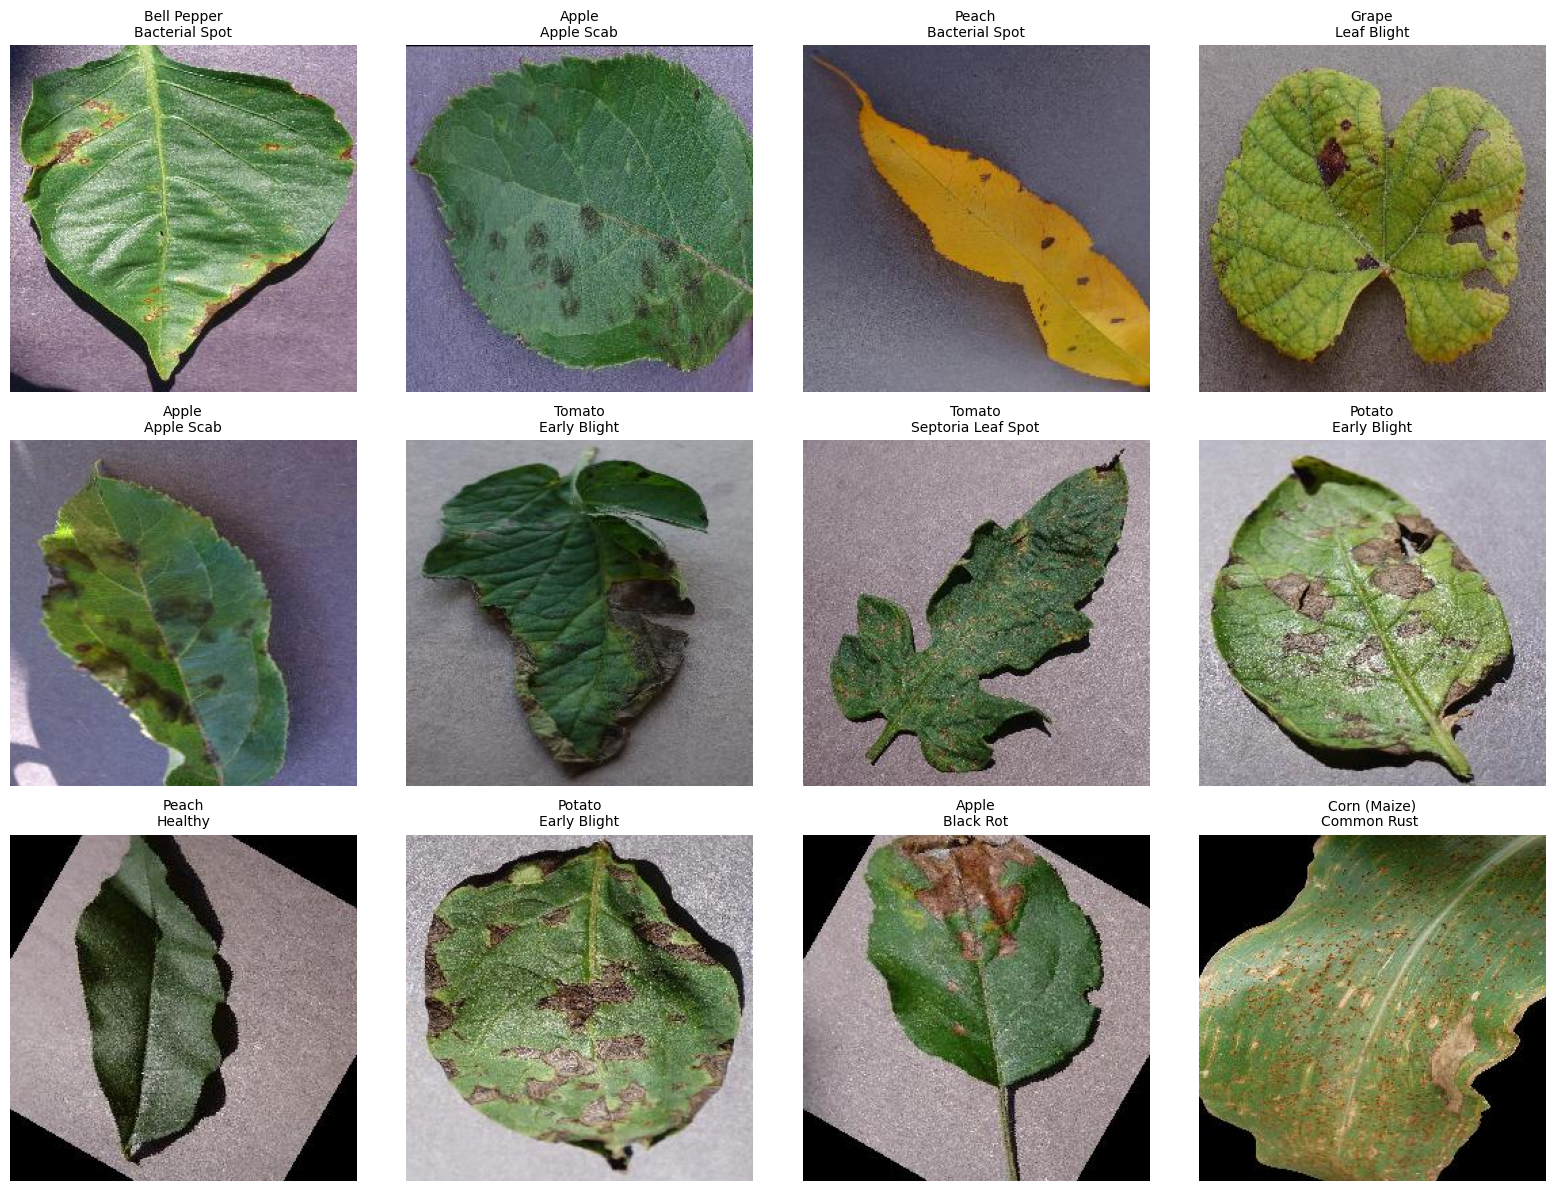


✓ Visual inspection grid generated.


In [ ]:
# ============================================================
# CELL-14 — VISUAL SAMPLE INSPECTION
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import random

print("=" * 70)
print("VISUAL SAMPLE INSPECTION")
print("=" * 70)

# Reproducible sampling
SEED = 42
random.seed(SEED)

sample_df = (
    manifest[manifest["split"] == "Train"]
    .sample(n=12, random_state=SEED)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    3, 4,
    figsize=(16, 12)
)

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):

    image = Image.open(row["path"]).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        f"{row['species']}\n{row['disease']}",
        fontsize=10
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("\n✓ Visual inspection grid generated.")

**Cell-15 — Define ConvNeXt-Tiny image transforms**

In [ ]:
# ============================================================
# CELL-15 — DEFINE IMAGE TRANSFORMS
# ============================================================

from torchvision import transforms

IMAGE_SIZE = 224

# ImageNet normalization used by pretrained ConvNeXt-Tiny
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# TRAIN TRANSFORMS
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ------------------------------------------------------------
# VALIDATION / TEST TRANSFORMS
# ------------------------------------------------------------

eval_transform = transforms.Compose([
    transforms.Resize(
        236
    ),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("=" * 70)
print("IMAGE TRANSFORMS")
print("=" * 70)

print("\nImage size:", IMAGE_SIZE)

print("\nTraining transform:")
print(train_transform)

print("\nValidation/Test transform:")
print(eval_transform)

print("\n✓ Transforms configured.")

IMAGE TRANSFORMS

Image size: 224

Training transform:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation/Test transform:
Compose(
    Resize(size=236, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

✓ Transforms configured.


**Cell-16 — PyTorch Dataset**

In [ ]:
# ============================================================
# CELL-16 — PYTORCH DATASET
# ============================================================

import torch
from torch.utils.data import Dataset

class PlantVillageDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        label = int(row["class_idx"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# CREATE SPLIT DATAFRAMES
# ------------------------------------------------------------

train_df = manifest[
    manifest["split"] == "Train"
].reset_index(drop=True)

val_df = manifest[
    manifest["split"] == "Val"
].reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "Test"
].reset_index(drop=True)


# ------------------------------------------------------------
# CREATE DATASETS
# ------------------------------------------------------------

train_dataset = PlantVillageDataset(
    train_df,
    transform=train_transform
)

val_dataset = PlantVillageDataset(
    val_df,
    transform=eval_transform
)

test_dataset = PlantVillageDataset(
    test_df,
    transform=eval_transform
)


print("=" * 70)
print("PYTORCH DATASETS")
print("=" * 70)

print(f"\nTrain dataset: {len(train_dataset):,}")
print(f"Validation dataset: {len(val_dataset):,}")
print(f"Test dataset: {len(test_dataset):,}")

print(f"\nNumber of classes: {len(CLASS_NAMES)}")

print("\n✓ PyTorch datasets created.")

PYTORCH DATASETS

Train dataset: 53,693
Validation dataset: 12,067
Test dataset: 1,358

Number of classes: 29

✓ PyTorch datasets created.


**Cell-17 — Dataset sanity check**

In [ ]:
# ============================================================
# CELL-17 — DATASET SANITY CHECK
# ============================================================

image, label = train_dataset[0]

print("=" * 70)
print("DATASET SANITY CHECK")
print("=" * 70)

print("\nImage tensor:")
print("  Type:", type(image))
print("  Shape:", image.shape)
print("  Dtype:", image.dtype)

print("\nLabel:")
print("  Type:", type(label))
print("  Value:", label)
print("  Class:", IDX_TO_CLASS[label])

print("\nTensor statistics:")
print("  Min:", image.min().item())
print("  Max:", image.max().item())
print("  Mean:", image.mean().item())
print("  Std:", image.std().item())

# Assertions
assert image.shape == (3, 224, 224)
assert image.dtype == torch.float32
assert 0 <= label < len(CLASS_NAMES)

print("\n✓ Image shape is correct: (3, 224, 224)")
print("✓ Image dtype is correct: float32")
print("✓ Label is within the valid 29-class range")
print("✓ Dataset sanity check passed.")

DATASET SANITY CHECK

Image tensor:
  Type: <class 'torch.Tensor'>
  Shape: torch.Size([3, 224, 224])
  Dtype: torch.float32

Label:
  Type: <class 'int'>
  Value: 0
  Class: Apple__Apple Scab

Tensor statistics:
  Min: -1.9124069213867188
  Max: 1.6639653444290161
  Mean: -0.1480581909418106
  Std: 0.8150238394737244

✓ Image shape is correct: (3, 224, 224)
✓ Image dtype is correct: float32
✓ Label is within the valid 29-class range
✓ Dataset sanity check passed.


**Cell-18 — Create efficient DataLoaders**

In [ ]:
# ============================================================
# CELL-18 — CREATE DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 64
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

print("=" * 70)
print("DATALOADERS")
print("=" * 70)

print(f"\nBatch size: {BATCH_SIZE}")
print(f"Workers: {NUM_WORKERS}")

print(f"\nTrain batches: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")
print(f"Test batches: {len(test_loader):,}")

print("\n✓ DataLoaders created.")

DATALOADERS

Batch size: 64
Workers: 2

Train batches: 839
Validation batches: 189
Test batches: 22

✓ DataLoaders created.


**Cell-19 — GPU batch sanity check**

In [ ]:
# ============================================================
# CELL-19 — GPU BATCH SANITY CHECK
# ============================================================

import torch

# Define device explicitly
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("GPU BATCH SANITY CHECK")
print("=" * 70)

print("\nSelected device:", device)

images, labels = next(iter(train_loader))

print("\nCPU batch:")
print("  Images:", images.shape, images.dtype)
print("  Labels:", labels.shape, labels.dtype)

# Move one batch to GPU
images_gpu = images.to(device, non_blocking=True)
labels_gpu = labels.to(device, non_blocking=True)

print("\nGPU batch:")
print("  Images:", images_gpu.shape)
print("  Device:", images_gpu.device)
print("  Labels:", labels_gpu.shape)
print("  Device:", labels_gpu.device)

# Basic checks
assert images_gpu.shape == (BATCH_SIZE, 3, 224, 224)
assert labels_gpu.shape == (BATCH_SIZE,)
assert images_gpu.device.type == "cuda"

print("\n✓ Batch shape is correct.")
print("✓ Images transferred to GPU successfully.")
print("✓ Labels transferred to GPU successfully.")

# Release test tensors
del images_gpu, labels_gpu

torch.cuda.empty_cache()

print("\n✓ GPU batch sanity check passed.")

GPU BATCH SANITY CHECK

Selected device: cuda

CPU batch:
  Images: torch.Size([64, 3, 224, 224]) torch.float32
  Labels: torch.Size([64]) torch.int64

GPU batch:
  Images: torch.Size([64, 3, 224, 224])
  Device: cuda:0
  Labels: torch.Size([64])
  Device: cuda:0

✓ Batch shape is correct.
✓ Images transferred to GPU successfully.
✓ Labels transferred to GPU successfully.

✓ GPU batch sanity check passed.


**Cell-20 — Load pretrained ConvNeXt-Tiny**

In [ ]:
# ============================================================
# CELL-20 — LOAD PRETRAINED CONVNEXT-TINY
# ============================================================

import torch
import torchvision
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

print("=" * 70)
print("LOADING PRETRAINED CONVNEXT-TINY")
print("=" * 70)

# ------------------------------------------------------------
# LOAD IMAGENET-PRETRAINED MODEL
# ------------------------------------------------------------

weights = ConvNeXt_Tiny_Weights.DEFAULT

model = convnext_tiny(
    weights=weights
)

print("\n✓ Pretrained ConvNeXt-Tiny loaded.")

# ------------------------------------------------------------
# INSPECT CLASSIFIER
# ------------------------------------------------------------

print("\nOriginal classifier:")
print(model.classifier)

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nParameter statistics:")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

# ------------------------------------------------------------
# MOVE MODEL TO GPU
# ------------------------------------------------------------

model = model.to(device)

print("\nModel device:", next(model.parameters()).device)

print("\n✓ ConvNeXt-Tiny is ready.")

LOADING PRETRAINED CONVNEXT-TINY
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 186MB/s]



✓ Pretrained ConvNeXt-Tiny loaded.

Original classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=1000, bias=True)
)

Parameter statistics:
  Total parameters:     28,589,128
  Trainable parameters: 28,589,128

Model device: cuda:0

✓ ConvNeXt-Tiny is ready.


**Cell-21 — Replace the classifier**

In [ ]:
# ============================================================
# CELL-21 — REPLACE CONVNEXT CLASSIFIER
# ============================================================

import torch.nn as nn

NUM_CLASSES = len(CLASS_NAMES)

# Replace ImageNet classifier with PlantVillage classifier
model.classifier[2] = nn.Linear(
    in_features=768,
    out_features=NUM_CLASSES
)

model = model.to(device)

print("=" * 70)
print("CONVNEXT CLASSIFIER UPDATED")
print("=" * 70)

print("\nNew classifier:")
print(model.classifier)

print("\nNumber of classes:", NUM_CLASSES)

# Parameter statistics
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nParameter statistics:")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

print("\n✓ ConvNeXt classifier now outputs 29 PlantVillage classes.")

CONVNEXT CLASSIFIER UPDATED

New classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=29, bias=True)
)

Number of classes: 29

Parameter statistics:
  Total parameters:     27,842,429
  Trainable parameters: 27,842,429

✓ ConvNeXt classifier now outputs 29 PlantVillage classes.


**Cell-22 — Forward-pass sanity check**

In [ ]:
# ============================================================
# CELL-22 — CONVNEXT FORWARD-PASS SANITY CHECK
# ============================================================

print("=" * 70)
print("CONVNEXT FORWARD-PASS SANITY CHECK")
print("=" * 70)

# Get one real batch
images, labels = next(iter(train_loader))

# Move batch to GPU
images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

# Evaluation mode for this sanity check
model.eval()

with torch.inference_mode():
    logits = model(images)

print("\nInput:")
print("  Shape:", images.shape)
print("  Device:", images.device)

print("\nOutput logits:")
print("  Shape:", logits.shape)
print("  Device:", logits.device)
print("  Dtype:", logits.dtype)

print("\nLabels:")
print("  Shape:", labels.shape)
print("  Device:", labels.device)

# Verify expected dimensions
assert logits.shape == (BATCH_SIZE, NUM_CLASSES)
assert labels.shape == (BATCH_SIZE,)

print("\n✓ Input shape is correct.")
print("✓ ConvNeXt forward pass succeeded.")
print(f"✓ Output shape is correct: ({BATCH_SIZE}, {NUM_CLASSES})")

# Release temporary tensors
del images, labels, logits

torch.cuda.empty_cache()

print("\n✓ Forward-pass sanity check passed.")

CONVNEXT FORWARD-PASS SANITY CHECK

Input:
  Shape: torch.Size([64, 3, 224, 224])
  Device: cuda:0

Output logits:
  Shape: torch.Size([64, 29])
  Device: cuda:0
  Dtype: torch.float32

Labels:
  Shape: torch.Size([64])
  Device: cuda:0

✓ Input shape is correct.
✓ ConvNeXt forward pass succeeded.
✓ Output shape is correct: (64, 29)

✓ Forward-pass sanity check passed.


**Cell-23 — Freeze ConvNeXt backbone**

In [ ]:
# ============================================================
# CELL-23 — FREEZE BACKBONE FOR STAGE 1
# ============================================================

print("=" * 70)
print("FREEZING CONVNEXT BACKBONE")
print("=" * 70)

# Freeze everything first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in model.classifier[2].parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# PARAMETER STATISTICS
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params


print("\nParameter statistics:")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Frozen parameters:    {frozen_params:,}")

print(
    f"\nTrainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

# ------------------------------------------------------------
# VERIFY CLASSIFIER
# ------------------------------------------------------------

print("\nFinal classifier:")
print(model.classifier[2])

print("\n✓ Backbone frozen.")
print("✓ Only the 29-class classification layer is trainable.")
print("✓ Stage 1 configuration ready.")

FREEZING CONVNEXT BACKBONE

Parameter statistics:
  Total parameters:     27,842,429
  Trainable parameters: 22,301
  Frozen parameters:    27,820,128

Trainable percentage: 0.08%

Final classifier:
Linear(in_features=768, out_features=29, bias=True)

✓ Backbone frozen.
✓ Only the 29-class classification layer is trainable.
✓ Stage 1 configuration ready.


**Cell-24 — Configure Stage-1 training**

In [ ]:
# ============================================================
# CELL-24 — STAGE-1 TRAINING CONFIGURATION
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# TRAINING HYPERPARAMETERS
# ------------------------------------------------------------

STAGE1_EPOCHS = 3

STAGE1_LR = 1e-3

WEIGHT_DECAY = 1e-4

LABEL_SMOOTHING = 0.1

# ------------------------------------------------------------
# LOSS FUNCTION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.classifier[2].parameters(),
    lr=STAGE1_LR,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# AMP CONFIGURATION
# ------------------------------------------------------------

AMP_ENABLED = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)

# ------------------------------------------------------------
# DISPLAY CONFIGURATION
# ------------------------------------------------------------

print("=" * 70)
print("STAGE-1 TRAINING CONFIGURATION")
print("=" * 70)

print(f"\nEpochs:          {STAGE1_EPOCHS}")
print(f"Learning rate:   {STAGE1_LR}")
print(f"Weight decay:    {WEIGHT_DECAY}")
print(f"Label smoothing: {LABEL_SMOOTHING}")
print(f"Optimizer:       AdamW")
print(f"AMP enabled:     {AMP_ENABLED}")

print("\nTrainable parameters:")
print(f"  {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

print("\n✓ Stage-1 training configuration ready.")

STAGE-1 TRAINING CONFIGURATION

Epochs:          3
Learning rate:   0.001
Weight decay:    0.0001
Label smoothing: 0.1
Optimizer:       AdamW
AMP enabled:     True

Trainable parameters:
  22,301

✓ Stage-1 training configuration ready.


**Cell-25 — Stage-1 training loop**

In [ ]:
# ============================================================
# CELL-25 — STAGE-1 TRAINING LOOP
# ============================================================

import time
from tqdm.auto import tqdm

print("=" * 70)
print("STAGE-1 CONVNEXT TRAINING")
print("=" * 70)

best_val_acc = 0.0
best_stage1_state = None

stage1_history = []

for epoch in range(1, STAGE1_EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    # Keep frozen backbone in evaluation mode
    # This prevents unwanted BatchNorm/normalization state updates.
    model.features.eval()

    running_loss = 0.0
    running_correct = 0
    running_samples = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{STAGE1_EPOCHS} [Train]"
    )

    for images, labels in train_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Statistics
        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        running_correct += (
            predictions == labels
        ).sum().item()

        running_samples += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / running_samples
    train_acc = running_correct / running_samples

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_samples = 0

    with torch.inference_mode():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch}/{STAGE1_EPOCHS} [Val]"
        )

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            batch_size = labels.size(0)

            val_loss_total += (
                loss.item() * batch_size
            )

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_samples += batch_size

    val_loss = val_loss_total / val_samples
    val_acc = val_correct / val_samples

    epoch_time = time.time() - epoch_start

    # ========================================================
    # SAVE BEST STAGE-1 MODEL
    # ========================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_stage1_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        best_marker = " ← BEST"

    else:
        best_marker = ""

    # ========================================================
    # RECORD HISTORY
    # ========================================================

    stage1_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "time_sec": epoch_time
    })

    print(
        f"\nEpoch {epoch}/{STAGE1_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Train Acc: {train_acc:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Acc: {val_acc:.4f}"
        f" | Time: {epoch_time:.1f}s"
        f"{best_marker}"
    )

# ============================================================
# RESTORE BEST STAGE-1 MODEL
# ============================================================

if best_stage1_state is not None:

    model.load_state_dict(
        best_stage1_state
    )

    print(
        f"\n✓ Restored best Stage-1 model."
        f" Best validation accuracy: "
        f"{best_val_acc:.4f}"
    )

print("\n✓ Stage-1 training completed.")

STAGE-1 CONVNEXT TRAINING


Epoch 1/3 [Train]:   0%|          | 0/839 [00:00<?, ?it/s]

Epoch 1/3 [Val]:   0%|          | 0/189 [00:00<?, ?it/s]


Epoch 1/3 | Train Loss: 0.9918 | Train Acc: 0.9371 | Val Loss: 0.8297 | Val Acc: 0.9770 | Time: 501.2s ← BEST


Epoch 2/3 [Train]:   0%|          | 0/839 [00:00<?, ?it/s]

Epoch 2/3 [Val]:   0%|          | 0/189 [00:00<?, ?it/s]


Epoch 2/3 | Train Loss: 0.8094 | Train Acc: 0.9816 | Val Loss: 0.7946 | Val Acc: 0.9830 | Time: 498.3s ← BEST


Epoch 3/3 [Train]:   0%|          | 0/839 [00:00<?, ?it/s]

Epoch 3/3 [Val]:   0%|          | 0/189 [00:00<?, ?it/s]


Epoch 3/3 | Train Loss: 0.7864 | Train Acc: 0.9863 | Val Loss: 0.7788 | Val Acc: 0.9870 | Time: 524.1s ← BEST

✓ Restored best Stage-1 model. Best validation accuracy: 0.9870

✓ Stage-1 training completed.


**Cell-26 — Inspect ConvNeXt feature stages**

In [ ]:
# ============================================================
# CELL-26 — INSPECT CONVNEXT FEATURE STAGES
# ============================================================

print("=" * 70)
print("CONVNEXT FEATURE STAGES")
print("=" * 70)

for idx, layer in enumerate(model.features):
    print(f"\nFeature block [{idx}]:")
    print(layer)

print("\n✓ Feature-stage inspection completed.")

CONVNEXT FEATURE STAGES

Feature block [0]:
Conv2dNormActivation(
  (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
  (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
)

Feature block [1]:
Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=96, out_features=384, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=384, out_features=96, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.0, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=96, out_features=384, bias=True)
      (4): GELU(approximate='none')
     

**Cell-27 — Configure Stage-2 fine-tuning**

In [ ]:
# ============================================================
# CELL-27 — STAGE-2 FINE-TUNING CONFIGURATION
# ============================================================

print("=" * 70)
print("STAGE-2 CONVNEXT FINE-TUNING")
print("=" * 70)

# ------------------------------------------------------------
# 1. FREEZE EVERYTHING
# ------------------------------------------------------------

for param in model.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# 2. UNFREEZE FINAL CONVNEXT FEATURE STAGE
# ------------------------------------------------------------

for param in model.features[7].parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# 3. UNFREEZE CLASSIFIER
# ------------------------------------------------------------

for param in model.classifier.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# 4. COUNT PARAMETERS
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params


print("\nParameter statistics:")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Frozen parameters:    {frozen_params:,}")

print(
    f"\nTrainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)


# ------------------------------------------------------------
# 5. SHOW WHICH MAJOR BLOCKS ARE TRAINABLE
# ------------------------------------------------------------

print("\nTrainable blocks:")

for name, module in [
    ("Final feature stage [7]", model.features[7]),
    ("Classifier", model.classifier)
]:

    module_params = sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

    print(
        f"  {name}: "
        f"{module_params:,} parameters"
    )


print("\n✓ Early/mid ConvNeXt features remain frozen.")
print("✓ Final feature stage is trainable.")
print("✓ Classifier is trainable.")
print("✓ Stage-2 fine-tuning configuration ready.")

STAGE-2 CONVNEXT FINE-TUNING

Parameter statistics:
  Total parameters:     27,842,429
  Trainable parameters: 14,313,245
  Frozen parameters:    13,529,184

Trainable percentage: 51.41%

Trainable blocks:
  Final feature stage [7]: 14,289,408 parameters
  Classifier: 23,837 parameters

✓ Early/mid ConvNeXt features remain frozen.
✓ Final feature stage is trainable.
✓ Classifier is trainable.
✓ Stage-2 fine-tuning configuration ready.


**Cell-28 — Stage-2 optimizer + scheduler**

In [ ]:
# ============================================================
# CELL-28 — STAGE-2 OPTIMIZER AND SCHEDULER
# ============================================================

STAGE2_EPOCHS = 4

FEATURE_LR = 1e-5
CLASSIFIER_LR = 5e-4

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features[7].parameters(),
            "lr": FEATURE_LR
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=STAGE2_EPOCHS
)

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

AMP_ENABLED = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)

print("=" * 70)
print("STAGE-2 TRAINING CONFIGURATION")
print("=" * 70)

print(f"\nEpochs:             {STAGE2_EPOCHS}")
print(f"Feature stage LR:   {FEATURE_LR}")
print(f"Classifier LR:      {CLASSIFIER_LR}")
print(f"Weight decay:       {WEIGHT_DECAY}")
print(f"Label smoothing:    {LABEL_SMOOTHING}")
print(f"Scheduler:          CosineAnnealingLR")
print(f"AMP enabled:        {AMP_ENABLED}")

print("\nOptimizer parameter groups:")

for i, group in enumerate(optimizer.param_groups):
    print(
        f"  Group {i}: "
        f"LR={group['lr']:.1e}, "
        f"parameters={sum(p.numel() for p in group['params']):,}"
    )

print("\n✓ Differential learning rates configured.")
print("✓ Final ConvNeXt stage will adapt slowly.")
print("✓ Classifier will learn faster.")
print("✓ Stage-2 optimizer is ready.")

STAGE-2 TRAINING CONFIGURATION

Epochs:             4
Feature stage LR:   1e-05
Classifier LR:      0.0005
Weight decay:       0.0001
Label smoothing:    0.1
Scheduler:          CosineAnnealingLR
AMP enabled:        True

Optimizer parameter groups:
  Group 0: LR=1.0e-05, parameters=14,289,408
  Group 1: LR=5.0e-04, parameters=23,837

✓ Differential learning rates configured.
✓ Final ConvNeXt stage will adapt slowly.
✓ Classifier will learn faster.
✓ Stage-2 optimizer is ready.


**Cell-29 — Stage-2 fine-tuning**

In [ ]:
# ============================================================
# CELL-29 — STAGE-2 CONVNEXT FINE-TUNING
# ============================================================

import copy
import time
import torch

best_val_acc_stage2 = 0.0
best_model_state_stage2 = None

stage2_history = []

print("=" * 70)
print("STARTING STAGE-2 CONVNEXT FINE-TUNING")
print("=" * 70)

for epoch in range(STAGE2_EPOCHS):

    epoch_start = time.time()

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    # --------------------------------------------------------
    # SCHEDULER
    # --------------------------------------------------------
    scheduler.step()

    current_feature_lr = optimizer.param_groups[0]["lr"]
    current_classifier_lr = optimizer.param_groups[1]["lr"]

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------
    stage2_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "feature_lr": current_feature_lr,
        "classifier_lr": current_classifier_lr,
        "time_sec": epoch_time
    })

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------
    if val_acc > best_val_acc_stage2:

        best_val_acc_stage2 = val_acc

        best_model_state_stage2 = copy.deepcopy(
            model.state_dict()
        )

        best_marker = " ← BEST"

    else:
        best_marker = ""

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------
    print(
        f"\nEpoch {epoch + 1}/{STAGE2_EPOCHS}"
        f"{best_marker}"
    )

    print(
        f"  Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f}"
    )

    print(
        f"  Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f}"
    )

    print(
        f"  Feature LR: {current_feature_lr:.2e} | "
        f"Classifier LR: {current_classifier_lr:.2e}"
    )

    print(
        f"  Time: {epoch_time:.1f}s"
    )

# ------------------------------------------------------------
# RESTORE BEST MODEL
# ------------------------------------------------------------

if best_model_state_stage2 is not None:

    model.load_state_dict(
        best_model_state_stage2
    )

print("\n" + "=" * 70)
print("STAGE-2 TRAINING COMPLETE")
print("=" * 70)

print(
    f"\nBest Stage-2 Validation Accuracy: "
    f"{best_val_acc_stage2:.4f}"
)

print("✓ Best model weights restored.")

STARTING STAGE-2 CONVNEXT FINE-TUNING

Epoch 1/4 ← BEST
  Train Loss: 0.7852 | Train Acc: 0.9857
  Val Loss:   0.7595 | Val Acc:    0.9915
  Feature LR: 8.54e-06 | Classifier LR: 4.27e-04
  Time: 531.4s

Epoch 2/4 ← BEST
  Train Loss: 0.7638 | Train Acc: 0.9894
  Val Loss:   0.7464 | Val Acc:    0.9920
  Feature LR: 5.00e-06 | Classifier LR: 2.50e-04
  Time: 557.9s

Epoch 3/4 ← BEST
  Train Loss: 0.7512 | Train Acc: 0.9916
  Val Loss:   0.7379 | Val Acc:    0.9930
  Feature LR: 1.46e-06 | Classifier LR: 7.32e-05
  Time: 533.6s

Epoch 4/4
  Train Loss: 0.7454 | Train Acc: 0.9926
  Val Loss:   0.7357 | Val Acc:    0.9930
  Feature LR: 0.00e+00 | Classifier LR: 0.00e+00
  Time: 535.6s

STAGE-2 TRAINING COMPLETE

Best Stage-2 Validation Accuracy: 0.9930
✓ Best model weights restored.


**Cell-30 — Final ConvNeXt test evaluation**

In [ ]:
# ============================================================
# CELL-30 — CONVNEXT TEST SET EVALUATION
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

print("=" * 70)
print("CONVNEXT — FINAL TEST EVALUATION")
print("=" * 70)

model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):
            outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probabilities.append(
            probabilities.cpu()
        )

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

all_probabilities = torch.cat(
    all_probabilities,
    dim=0
).numpy()

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

print("\nOverall Test Metrics:")
print(f"  Test Accuracy:          {test_accuracy:.4f}")
print(f"  Macro Precision:        {precision:.4f}")
print(f"  Macro Recall:           {recall:.4f}")
print(f"  Macro F1:               {f1:.4f}")
print(f"  Weighted Precision:     {weighted_precision:.4f}")
print(f"  Weighted Recall:        {weighted_recall:.4f}")
print(f"  Weighted F1:            {weighted_f1:.4f}")

print("\nTest samples evaluated:", len(all_labels))

print("\n✓ Predictions collected.")
print("✓ Class probabilities collected.")
print("✓ Final test evaluation completed.")

CONVNEXT — FINAL TEST EVALUATION

Overall Test Metrics:
  Test Accuracy:          0.9934
  Macro Precision:        0.9935
  Macro Recall:           0.9934
  Macro F1:               0.9934
  Weighted Precision:     0.9935
  Weighted Recall:        0.9934
  Weighted F1:            0.9934

Test samples evaluated: 1358

✓ Predictions collected.
✓ Class probabilities collected.
✓ Final test evaluation completed.


**Cell-31 — Confusion Matrix + Per-Class Performance**

CONVNEXT — CONFUSION MATRIX & PER-CLASS PERFORMANCE


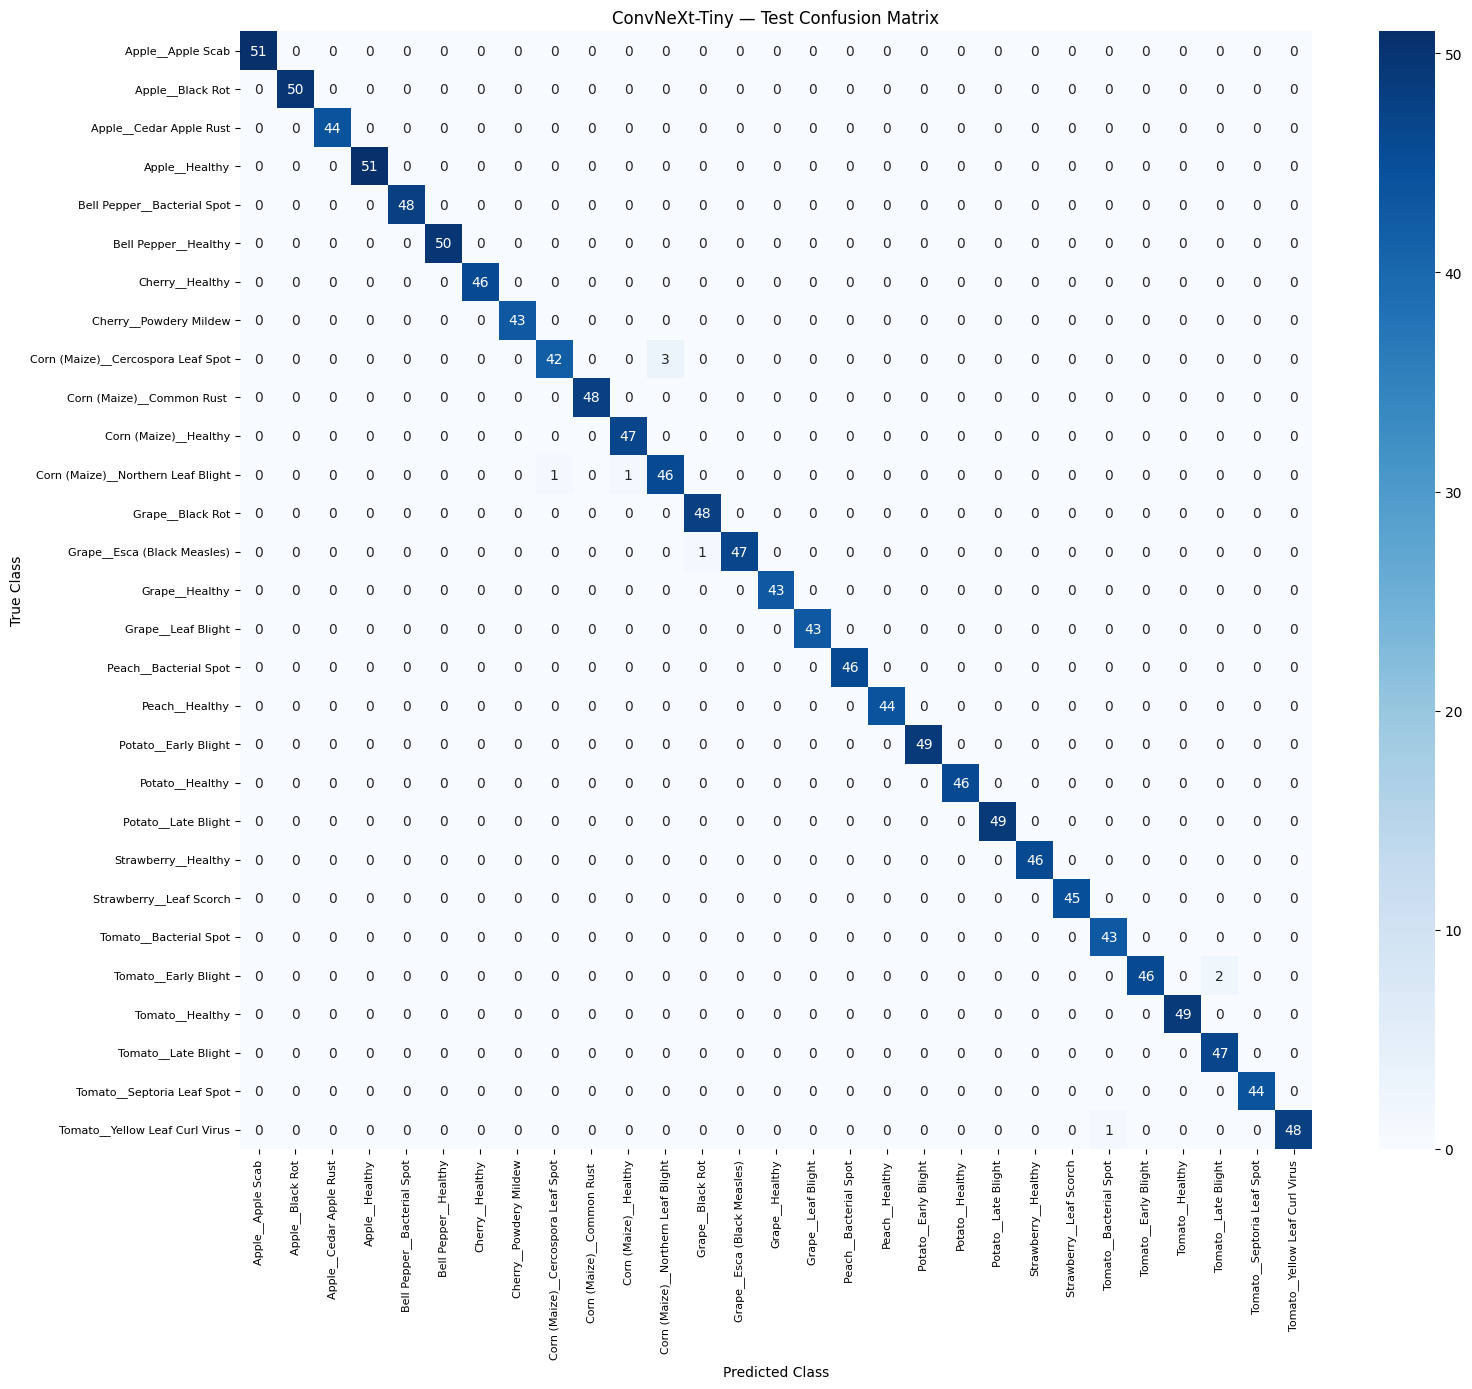


Classification Report:

                                    precision    recall  f1-score   support

                 Apple__Apple Scab     1.0000    1.0000    1.0000        51
                  Apple__Black Rot     1.0000    1.0000    1.0000        50
           Apple__Cedar Apple Rust     1.0000    1.0000    1.0000        44
                    Apple__Healthy     1.0000    1.0000    1.0000        51
       Bell Pepper__Bacterial Spot     1.0000    1.0000    1.0000        48
              Bell Pepper__Healthy     1.0000    1.0000    1.0000        50
                   Cherry__Healthy     1.0000    1.0000    1.0000        46
            Cherry__Powdery Mildew     1.0000    1.0000    1.0000        43
Corn (Maize)__Cercospora Leaf Spot     0.9767    0.9333    0.9545        45
        Corn (Maize)__Common Rust      1.0000    1.0000    1.0000        48
             Corn (Maize)__Healthy     0.9792    1.0000    0.9895        47
Corn (Maize)__Northern Leaf Blight     0.9388    0.9583    0.9

In [ ]:
# ============================================================
# CELL-31 — CONFUSION MATRIX + PER-CLASS PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("CONVNEXT — CONFUSION MATRIX & PER-CLASS PERFORMANCE")
print("=" * 70)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(
    figsize=(16, 14)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("ConvNeXt-Tiny — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

# ------------------------------------------------------------
# MOST CONFUSED CLASS PAIRS
# ------------------------------------------------------------

cm_no_diag = cm.copy()

np.fill_diagonal(
    cm_no_diag,
    0
)

confused_indices = np.dstack(
    np.unravel_index(
        np.argsort(cm_no_diag.ravel())[::-1],
        cm_no_diag.shape
    )
)[0]

print("\nTop Confused Class Pairs:")

shown = 0

for true_idx, pred_idx in confused_indices:

    count = cm_no_diag[
        true_idx,
        pred_idx
    ]

    if count == 0:
        break

    print(
        f"  True: {CLASS_NAMES[true_idx]}"
        f" → Predicted: {CLASS_NAMES[pred_idx]}"
        f" | Errors: {count}"
    )

    shown += 1

    if shown >= 10:
        break

print("\n✓ Confusion matrix generated.")
print("✓ Per-class metrics calculated.")
print("✓ Top confusion pairs identified.")

**Cell-32 — Confidence analysis**

In [ ]:
# ============================================================
# CELL-32 — CONVNEXT CONFIDENCE & ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CONVNEXT — CONFIDENCE & ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# PREDICTION CONFIDENCE
# ------------------------------------------------------------

prediction_confidence = all_probabilities.max(axis=1)

correct_mask = (
    all_predictions == all_labels
)

incorrect_mask = ~correct_mask

correct_confidences = prediction_confidence[
    correct_mask
]

incorrect_confidences = prediction_confidence[
    incorrect_mask
]

print("\nPrediction statistics:")

print(f"  Total predictions:      {len(all_labels):,}")
print(f"  Correct predictions:    {correct_mask.sum():,}")
print(f"  Incorrect predictions:  {incorrect_mask.sum():,}")

print(
    f"\nOverall mean confidence: "
    f"{prediction_confidence.mean():.4f}"
)

print(
    f"Mean confidence — correct: "
    f"{correct_confidences.mean():.4f}"
)

if len(incorrect_confidences) > 0:

    print(
        f"Mean confidence — incorrect: "
        f"{incorrect_confidences.mean():.4f}"
    )

    print(
        f"Maximum confidence on an incorrect prediction: "
        f"{incorrect_confidences.max():.4f}"
    )

    print(
        f"Minimum confidence on an incorrect prediction: "
        f"{incorrect_confidences.min():.4f}"
    )

# ------------------------------------------------------------
# HIGH-CONFIDENCE ERRORS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("HIGHEST-CONFIDENCE INCORRECT PREDICTIONS")
print("-" * 70)

error_indices = np.where(
    incorrect_mask
)[0]

sorted_error_indices = error_indices[
    np.argsort(
        prediction_confidence[error_indices]
    )[::-1]
]

error_rows = []

for idx in sorted_error_indices[:20]:

    error_rows.append({
        "index": int(idx),
        "true_class": CLASS_NAMES[
            all_labels[idx]
        ],
        "predicted_class": CLASS_NAMES[
            all_predictions[idx]
        ],
        "confidence": float(
            prediction_confidence[idx]
        )
    })

error_df = pd.DataFrame(error_rows)

if len(error_df) > 0:

    display(
        error_df.style.format({
            "confidence": "{:.4f}"
        })
    )

else:

    print("No incorrect predictions found.")

# ------------------------------------------------------------
# CONFIDENCE SUMMARY
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CONFIDENCE QUANTILES")
print("-" * 70)

for name, values in [
    ("Correct", correct_confidences),
    ("Incorrect", incorrect_confidences)
]:

    if len(values) == 0:
        continue

    q = np.percentile(
        values,
        [25, 50, 75, 90, 95]
    )

    print(f"\n{name} predictions:")

    print(f"  25th percentile: {q[0]:.4f}")
    print(f"  Median:          {q[1]:.4f}")
    print(f"  75th percentile: {q[2]:.4f}")
    print(f"  90th percentile: {q[3]:.4f}")
    print(f"  95th percentile: {q[4]:.4f}")

print("\n✓ Confidence analysis completed.")
print("✓ Incorrect predictions ranked by confidence.")
print("✓ Results ready for calibration/abstention analysis.")

CONVNEXT — CONFIDENCE & ERROR ANALYSIS

Prediction statistics:
  Total predictions:      1,358
  Correct predictions:    1,349
  Incorrect predictions:  9

Overall mean confidence: 0.8911
Mean confidence — correct: 0.8936
Mean confidence — incorrect: 0.5205
Maximum confidence on an incorrect prediction: 0.6890
Minimum confidence on an incorrect prediction: 0.3364

----------------------------------------------------------------------
HIGHEST-CONFIDENCE INCORRECT PREDICTIONS
----------------------------------------------------------------------


,index,true_class,predicted_class,confidence
0,1134,Tomato__Early Blight,Tomato__Late Blight,0.6890
1,405,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.6323
2,1165,Tomato__Early Blight,Tomato__Late Blight,0.5986
3,1310,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,0.5498
4,416,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.5176
5,400,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.4724
6,659,Grape__Esca (Black Measles),Grape__Black Rot,0.4631
7,532,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,0.4265
8,524,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.3364



----------------------------------------------------------------------
CONFIDENCE QUANTILES
----------------------------------------------------------------------

Correct predictions:
  25th percentile: 0.8711
  Median:          0.9258
  75th percentile: 0.9531
  90th percentile: 0.9736
  95th percentile: 0.9810

Incorrect predictions:
  25th percentile: 0.4631
  Median:          0.5176
  75th percentile: 0.5986
  90th percentile: 0.6437
  95th percentile: 0.6663

✓ Confidence analysis completed.
✓ Incorrect predictions ranked by confidence.
✓ Results ready for calibration/abstention analysis.


**Cell-33 — Expected Calibration Error (ECE) + Brier Score**

CONVNEXT — CALIBRATION ANALYSIS

Calibration Metrics:
  Expected Calibration Error (ECE): 0.1024
  Multiclass Brier Score: 0.0293

Calibration bins:
    0.2-0.3 | N=   1 | Confidence=0.2754 | Accuracy=1.0000 | Gap=0.7246
    0.3-0.4 | N=   7 | Confidence=0.3430 | Accuracy=0.8571 | Gap=0.5141
    0.4-0.5 | N=   7 | Confidence=0.4561 | Accuracy=0.5714 | Gap=0.1154
    0.5-0.6 | N=  24 | Confidence=0.5562 | Accuracy=0.8750 | Gap=0.3188
    0.6-0.7 | N=  43 | Confidence=0.6523 | Accuracy=0.9535 | Gap=0.3011
    0.7-0.8 | N=  92 | Confidence=0.7603 | Accuracy=1.0000 | Gap=0.2397
    0.8-0.9 | N= 325 | Confidence=0.8613 | Accuracy=1.0000 | Gap=0.1387
    0.9-1.0 | N= 859 | Confidence=0.9463 | Accuracy=1.0000 | Gap=0.0537


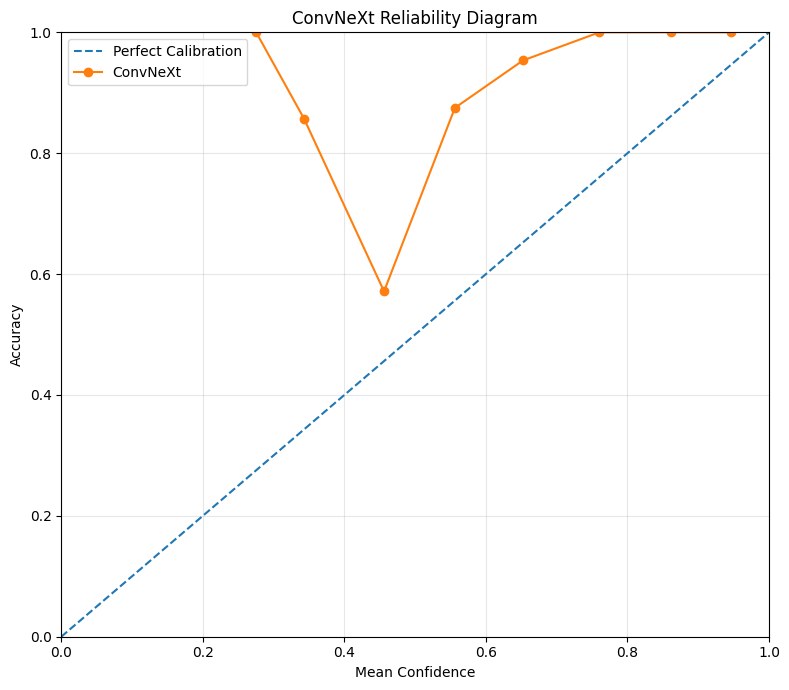


✓ ECE calculated.
✓ Brier score calculated.
✓ Reliability diagram generated.


In [ ]:
# ============================================================
# CELL-33 — CALIBRATION ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss

print("=" * 70)
print("CONVNEXT — CALIBRATION ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# CONFIDENCE / CORRECTNESS
# ------------------------------------------------------------

confidence = prediction_confidence
correct = correct_mask.astype(float)

# ------------------------------------------------------------
# EXPECTED CALIBRATION ERROR
# ------------------------------------------------------------

NUM_BINS = 10

bin_edges = np.linspace(
    0.0,
    1.0,
    NUM_BINS + 1
)

ece = 0.0

bin_results = []

for i in range(NUM_BINS):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == NUM_BINS - 1:
        mask = (
            (confidence >= lower)
            & (confidence <= upper)
        )
    else:
        mask = (
            (confidence >= lower)
            & (confidence < upper)
        )

    count = mask.sum()

    if count == 0:
        continue

    mean_confidence = confidence[mask].mean()
    accuracy = correct[mask].mean()

    gap = abs(
        accuracy - mean_confidence
    )

    weighted_gap = (
        count / len(confidence)
    ) * gap

    ece += weighted_gap

    bin_results.append({
        "bin": f"{lower:.1f}-{upper:.1f}",
        "samples": int(count),
        "confidence": mean_confidence,
        "accuracy": accuracy,
        "gap": gap
    })

# ------------------------------------------------------------
# MULTICLASS BRIER SCORE
# ------------------------------------------------------------

one_hot_labels = np.zeros_like(
    all_probabilities
)

one_hot_labels[
    np.arange(len(all_labels)),
    all_labels
] = 1

brier_score = np.mean(
    np.sum(
        (
            all_probabilities
            - one_hot_labels
        ) ** 2,
        axis=1
    )
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\nCalibration Metrics:")

print(
    f"  Expected Calibration Error (ECE): "
    f"{ece:.4f}"
)

print(
    f"  Multiclass Brier Score: "
    f"{brier_score:.4f}"
)

print("\nCalibration bins:")

for row in bin_results:

    print(
        f"  {row['bin']:>9} | "
        f"N={row['samples']:4d} | "
        f"Confidence={row['confidence']:.4f} | "
        f"Accuracy={row['accuracy']:.4f} | "
        f"Gap={row['gap']:.4f}"
    )

# ------------------------------------------------------------
# RELIABILITY DIAGRAM
# ------------------------------------------------------------

bin_confidences = [
    row["confidence"]
    for row in bin_results
]

bin_accuracies = [
    row["accuracy"]
    for row in bin_results
]

plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    bin_confidences,
    bin_accuracies,
    marker="o",
    label="ConvNeXt"
)

plt.xlabel("Mean Confidence")
plt.ylabel("Accuracy")
plt.title("ConvNeXt Reliability Diagram")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

print("\n✓ ECE calculated.")
print("✓ Brier score calculated.")
print("✓ Reliability diagram generated.")

**Cell-34 — Confidence-based Abstention / Risk-Coverage Analysis**

CONVNEXT — ABSTENTION / RISK-COVERAGE ANALYSIS

Selective prediction results:



,threshold,accepted,abstained,coverage,accuracy,risk
0,0.50,1343,15,0.9890,0.9963,0.0037
1,0.60,1319,39,0.9713,0.9985,0.0015
2,0.70,1276,82,0.9396,1.0000,0.0000
3,0.80,1184,174,0.8719,1.0000,0.0000
4,0.85,1080,278,0.7953,1.0000,0.0000
5,0.90,861,497,0.6340,1.0000,0.0000
6,0.95,384,974,0.2828,1.0000,0.0000
7,0.98,81,1277,0.0596,1.0000,0.0000


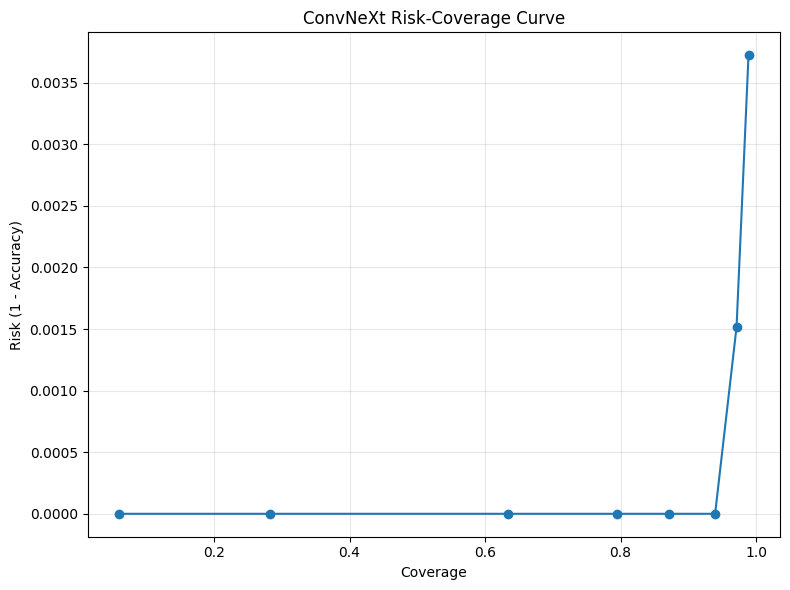


✓ Confidence thresholds evaluated.
✓ Coverage calculated.
✓ Selective accuracy calculated.
✓ Risk calculated.
✓ Risk-coverage curve generated.


In [ ]:
# ============================================================
# CELL-34 — CONFIDENCE-BASED ABSTENTION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("CONVNEXT — ABSTENTION / RISK-COVERAGE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# THRESHOLDS
# ------------------------------------------------------------

thresholds = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.95,
    0.98
]

results = []

for threshold in thresholds:

    accepted_mask = (
        prediction_confidence >= threshold
    )

    accepted_count = accepted_mask.sum()

    abstained_count = (
        len(prediction_confidence)
        - accepted_count
    )

    if accepted_count > 0:

        accepted_accuracy = (
            correct_mask[accepted_mask].mean()
        )

        risk = 1.0 - accepted_accuracy

        coverage = (
            accepted_count
            / len(prediction_confidence)
        )

    else:

        accepted_accuracy = np.nan
        risk = np.nan
        coverage = 0.0

    results.append({
        "threshold": threshold,
        "accepted": accepted_count,
        "abstained": abstained_count,
        "coverage": coverage,
        "accuracy": accepted_accuracy,
        "risk": risk
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("\nSelective prediction results:\n")

display(
    results_df.style.format({
        "threshold": "{:.2f}",
        "coverage": "{:.4f}",
        "accuracy": "{:.4f}",
        "risk": "{:.4f}"
    })
)

# ------------------------------------------------------------
# PLOT — RISK-COVERAGE CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    results_df["coverage"],
    results_df["risk"],
    marker="o"
)

plt.xlabel("Coverage")
plt.ylabel("Risk (1 - Accuracy)")
plt.title("ConvNeXt Risk-Coverage Curve")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Confidence thresholds evaluated.")
print("✓ Coverage calculated.")
print("✓ Selective accuracy calculated.")
print("✓ Risk calculated.")
print("✓ Risk-coverage curve generated.")

**Cell-35 — Build validation predictions for threshold selection**

In [ ]:
# ============================================================
# CELL-35 — VALIDATION PREDICTIONS FOR THRESHOLD SELECTION
# ============================================================

import numpy as np
import torch

print("=" * 70)
print("CONVNEXT — VALIDATION CONFIDENCE ANALYSIS")
print("=" * 70)

model.eval()

val_labels_list = []
val_predictions_list = []
val_probabilities_list = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):
            outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(
            dim=1
        )

        val_labels_list.extend(
            labels.cpu().numpy()
        )

        val_predictions_list.extend(
            predictions.cpu().numpy()
        )

        val_probabilities_list.append(
            probabilities.cpu()
        )

val_labels = np.array(
    val_labels_list
)

val_predictions = np.array(
    val_predictions_list
)

val_probabilities = torch.cat(
    val_probabilities_list,
    dim=0
).numpy()

val_confidence = val_probabilities.max(
    axis=1
)

val_correct = (
    val_predictions == val_labels
)

print("\nValidation samples:", len(val_labels))

print(
    f"Validation accuracy: "
    f"{val_correct.mean():.4f}"
)

print(
    f"Mean validation confidence: "
    f"{val_confidence.mean():.4f}"
)

print(
    f"Correct predictions: "
    f"{val_correct.sum():,}"
)

print(
    f"Incorrect predictions: "
    f"{(~val_correct).sum():,}"
)

print("\n✓ Validation probabilities collected.")
print("✓ Validation confidence calculated.")
print("✓ Test set remains untouched for final evaluation.")

CONVNEXT — VALIDATION CONFIDENCE ANALYSIS

Validation samples: 12067
Validation accuracy: 0.9930
Mean validation confidence: 0.8882
Correct predictions: 11,982
Incorrect predictions: 85

✓ Validation probabilities collected.
✓ Validation confidence calculated.
✓ Test set remains untouched for final evaluation.


**Cell-36 — Select abstention threshold from validation**

In [ ]:
# ============================================================
# CELL-36 — VALIDATION-BASED ABSTENTION THRESHOLD SELECTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CONVNEXT — VALIDATION-BASED THRESHOLD SELECTION")
print("=" * 70)

# ------------------------------------------------------------
# CANDIDATE THRESHOLDS
# ------------------------------------------------------------

candidate_thresholds = np.arange(
    0.50,
    1.00,
    0.01
)

threshold_results = []

for threshold in candidate_thresholds:

    accepted = (
        val_confidence >= threshold
    )

    accepted_count = accepted.sum()

    if accepted_count == 0:
        continue

    accepted_accuracy = (
        val_correct[accepted].mean()
    )

    coverage = (
        accepted_count
        / len(val_labels)
    )

    risk = 1.0 - accepted_accuracy

    threshold_results.append({
        "threshold": threshold,
        "accepted": accepted_count,
        "abstained": len(val_labels) - accepted_count,
        "coverage": coverage,
        "accuracy": accepted_accuracy,
        "risk": risk
    })

threshold_df = pd.DataFrame(
    threshold_results
)

# ------------------------------------------------------------
# FIND LOWEST THRESHOLD WITH ZERO VALIDATION RISK
# ------------------------------------------------------------

zero_risk = threshold_df[
    threshold_df["risk"] == 0.0
]

if len(zero_risk) > 0:

    selected_threshold = (
        zero_risk.iloc[0]["threshold"]
    )

    selected_row = zero_risk.iloc[0]

    print(
        "\nSelected threshold:"
        f" {selected_threshold:.2f}"
    )

    print(
        "\nValidation performance at selected threshold:"
    )

    print(
        f"  Coverage:   "
        f"{selected_row['coverage']:.4f}"
    )

    print(
        f"  Accuracy:   "
        f"{selected_row['accuracy']:.4f}"
    )

    print(
        f"  Risk:       "
        f"{selected_row['risk']:.4f}"
    )

    print(
        f"  Accepted:   "
        f"{int(selected_row['accepted']):,}"
    )

    print(
        f"  Abstained:  "
        f"{int(selected_row['abstained']):,}"
    )

else:

    # If zero validation risk is impossible,
    # select the threshold with minimum risk,
    # breaking ties using maximum coverage.

    min_risk = threshold_df["risk"].min()

    best_candidates = threshold_df[
        threshold_df["risk"] == min_risk
    ]

    selected_row = best_candidates.loc[
        best_candidates["coverage"].idxmax()
    ]

    selected_threshold = (
        selected_row["threshold"]
    )

    print(
        "\nNo zero-risk threshold found."
    )

    print(
        f"Selected minimum-risk threshold: "
        f"{selected_threshold:.2f}"
    )

# ------------------------------------------------------------
# SHOW ALL CANDIDATE RESULTS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("VALIDATION THRESHOLD RESULTS")
print("-" * 70)

display(
    threshold_df.style.format({
        "threshold": "{:.2f}",
        "coverage": "{:.4f}",
        "accuracy": "{:.4f}",
        "risk": "{:.4f}"
    })
)

print(
    "\n✓ Threshold selected using validation data only."
)

print(
    "✓ Test set has not been used for threshold selection."
)

CONVNEXT — VALIDATION-BASED THRESHOLD SELECTION

Selected threshold: 0.94

Validation performance at selected threshold:
  Coverage:   0.3735
  Accuracy:   1.0000
  Risk:       0.0000
  Accepted:   4,507
  Abstained:  7,560

----------------------------------------------------------------------
VALIDATION THRESHOLD RESULTS
----------------------------------------------------------------------


,threshold,accepted,abstained,coverage,accuracy,risk
0,0.50,11878,189,0.9843,0.9964,0.0036
1,0.51,11857,210,0.9826,0.9964,0.0036
2,0.52,11838,229,0.9810,0.9965,0.0035
3,0.53,11816,251,0.9792,0.9968,0.0032
4,0.54,11796,271,0.9775,0.9970,0.0030
5,0.55,11777,290,0.9760,0.9972,0.0028
6,0.56,11756,311,0.9742,0.9973,0.0027
7,0.57,11732,335,0.9722,0.9974,0.0026
8,0.58,11712,355,0.9706,0.9974,0.0026
9,0.59,11688,379,0.9686,0.9975,0.0025



✓ Threshold selected using validation data only.
✓ Test set has not been used for threshold selection.


**Cell-37 — Final unbiased abstention evaluation on Test**

In [ ]:
# ============================================================
# CELL-37 — FINAL TEST ABSTENTION EVALUATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CONVNEXT — FINAL TEST ABSTENTION EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# FROZEN THRESHOLD FROM VALIDATION
# ------------------------------------------------------------

ABSTENTION_THRESHOLD = float(
    selected_threshold
)

print(
    f"\nFrozen threshold from validation: "
    f"{ABSTENTION_THRESHOLD:.2f}"
)

# ------------------------------------------------------------
# APPLY THRESHOLD TO TEST SET
# ------------------------------------------------------------

test_accepted_mask = (
    prediction_confidence
    >= ABSTENTION_THRESHOLD
)

test_abstained_mask = ~test_accepted_mask

accepted_count = test_accepted_mask.sum()
abstained_count = test_abstained_mask.sum()

# ------------------------------------------------------------
# SELECTIVE PERFORMANCE
# ------------------------------------------------------------

if accepted_count > 0:

    selective_accuracy = (
        correct_mask[test_accepted_mask].mean()
    )

    selective_risk = (
        1.0 - selective_accuracy
    )

    coverage = (
        accepted_count
        / len(all_labels)
    )

else:

    selective_accuracy = np.nan
    selective_risk = np.nan
    coverage = 0.0

abstention_rate = (
    abstained_count
    / len(all_labels)
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\nFinal Test Results:")

print(
    f"  Total test samples:       "
    f"{len(all_labels):,}"
)

print(
    f"  Accepted predictions:     "
    f"{accepted_count:,}"
)

print(
    f"  Abstained predictions:    "
    f"{abstained_count:,}"
)

print(
    f"  Coverage:                 "
    f"{coverage:.4f}"
)

print(
    f"  Abstention rate:          "
    f"{abstention_rate:.4f}"
)

print(
    f"  Selective accuracy:       "
    f"{selective_accuracy:.4f}"
)

print(
    f"  Selective risk:           "
    f"{selective_risk:.4f}"
)

# ------------------------------------------------------------
# COMPARE WITH ORDINARY CLASSIFICATION
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ORDINARY vs ABSTENTION-AWARE CLASSIFICATION")
print("-" * 70)

print(
    f"\nOrdinary test accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Abstention-aware accuracy: "
    f"{selective_accuracy:.4f}"
)

print(
    f"Coverage reduction: "
    f"{1.0 - coverage:.4f}"
)

print(
    f"Accuracy improvement: "
    f"{selective_accuracy - test_accuracy:.4f}"
)

print("\n✓ Validation-derived threshold applied.")
print("✓ Test set evaluated only once with frozen threshold.")
print("✓ Final abstention-aware test result obtained.")

CONVNEXT — FINAL TEST ABSTENTION EVALUATION

Frozen threshold from validation: 0.94

Final Test Results:
  Total test samples:       1,358
  Accepted predictions:     515
  Abstained predictions:    843
  Coverage:                 0.3792
  Abstention rate:          0.6208
  Selective accuracy:       1.0000
  Selective risk:           0.0000

----------------------------------------------------------------------
ORDINARY vs ABSTENTION-AWARE CLASSIFICATION
----------------------------------------------------------------------

Ordinary test accuracy: 0.9934
Abstention-aware accuracy: 1.0000
Coverage reduction: 0.6208
Accuracy improvement: 0.0066

✓ Validation-derived threshold applied.
✓ Test set evaluated only once with frozen threshold.
✓ Final abstention-aware test result obtained.


**Cell-38 — Validation Risk-Coverage + AURC**

CONVNEXT — VALIDATION RISK-COVERAGE ANALYSIS

Validation Risk-Coverage Metrics:
  AURC: 0.000372
  Minimum risk: 0.000000
  Maximum risk: 0.007044

Risk at selected coverage levels:
  Coverage=0.0999 | Risk=0.000000 | Accuracy=1.000000 | Confidence threshold=0.9731
  Coverage=0.2000 | Risk=0.000000 | Accuracy=1.000000 | Confidence threshold=0.9609
  Coverage=0.3000 | Risk=0.000000 | Accuracy=1.000000 | Confidence threshold=0.9492
  Coverage=0.3999 | Risk=0.000000 | Accuracy=1.000000 | Confidence threshold=0.9370
  Coverage=0.5000 | Risk=0.000166 | Accuracy=0.999834 | Confidence threshold=0.9233
  Coverage=0.6000 | Risk=0.000138 | Accuracy=0.999862 | Confidence threshold=0.9058
  Coverage=0.6999 | Risk=0.000118 | Accuracy=0.999882 | Confidence threshold=0.8818
  Coverage=0.8000 | Risk=0.000311 | Accuracy=0.999689 | Confidence threshold=0.8428
  Coverage=0.9000 | Risk=0.001105 | Accuracy=0.998895 | Confidence threshold=0.7598
  Coverage=1.0000 | Risk=0.007044 | Accuracy=0.992956 | Confid

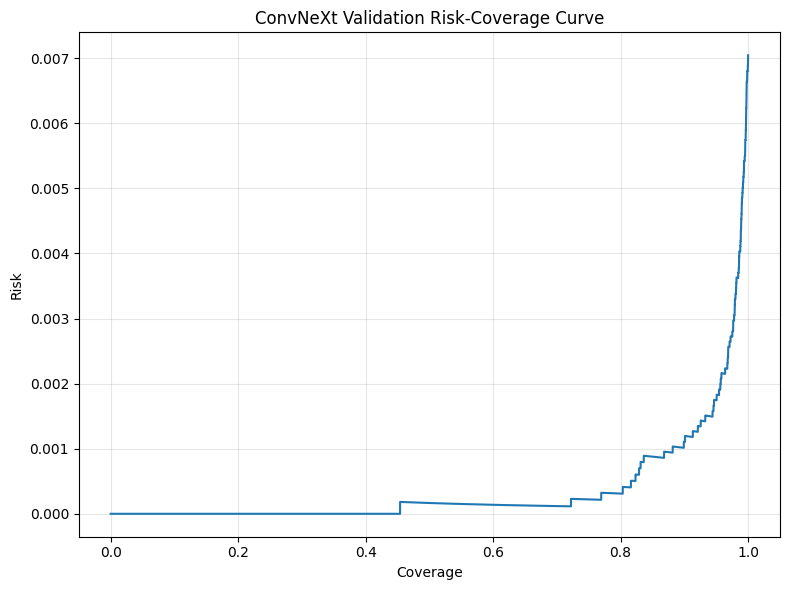


✓ Validation risk-coverage curve calculated.
✓ AURC calculated.
✓ Multiple coverage levels evaluated.


In [ ]:
# ============================================================
# CELL-38 — VALIDATION RISK-COVERAGE CURVE + AURC
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CONVNEXT — VALIDATION RISK-COVERAGE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# SORT VALIDATION SAMPLES BY CONFIDENCE
# ------------------------------------------------------------

sort_indices = np.argsort(
    -val_confidence
)

sorted_correct = (
    val_correct[sort_indices]
)

sorted_confidence = (
    val_confidence[sort_indices]
)

# ------------------------------------------------------------
# CALCULATE RISK AT DIFFERENT COVERAGES
# ------------------------------------------------------------

n = len(sorted_correct)

coverage_values = (
    np.arange(1, n + 1) / n
)

cumulative_errors = np.cumsum(
    ~sorted_correct
)

risk_values = (
    cumulative_errors
    / np.arange(1, n + 1)
)

# ------------------------------------------------------------
# AURC
# ------------------------------------------------------------

aurc = np.trapezoid(
    risk_values,
    coverage_values
)

print("\nValidation Risk-Coverage Metrics:")

print(
    f"  AURC: {aurc:.6f}"
)

print(
    f"  Minimum risk: "
    f"{risk_values.min():.6f}"
)

print(
    f"  Maximum risk: "
    f"{risk_values.max():.6f}"
)

# ------------------------------------------------------------
# SELECTED COVERAGE POINTS
# ------------------------------------------------------------

target_coverages = [
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    1.00
]

print("\nRisk at selected coverage levels:")

for target in target_coverages:

    idx = min(
        int(target * n) - 1,
        n - 1
    )

    print(
        f"  Coverage={coverage_values[idx]:.4f}"
        f" | Risk={risk_values[idx]:.6f}"
        f" | Accuracy={1.0 - risk_values[idx]:.6f}"
        f" | Confidence threshold="
        f"{sorted_confidence[idx]:.4f}"
    )

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    coverage_values,
    risk_values
)

plt.xlabel("Coverage")
plt.ylabel("Risk")
plt.title(
    "ConvNeXt Validation Risk-Coverage Curve"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Validation risk-coverage curve calculated.")
print("✓ AURC calculated.")
print("✓ Multiple coverage levels evaluated.")

**Cell-39 — Save ConvNeXt experimental results**

In [ ]:
# ============================================================
# CELL-39 — SAVE CONVNEXT EXPERIMENT RESULTS
# ============================================================

import json
from pathlib import Path

RESULTS_DIR = Path(
    "/content/convnext_results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

convnext_results = {
    "model": "ConvNeXt-Tiny",

    "dataset": "PlantVillage Dataset Updated",

    "num_classes": len(CLASS_NAMES),

    "image_size": IMAGE_SIZE,

    "train_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),

    "stage1": {
        "epochs": STAGE1_EPOCHS,
        "learning_rate": STAGE1_LR,
        "best_validation_accuracy": 0.9870
    },

    "stage2": {
        "epochs": STAGE2_EPOCHS,
        "feature_learning_rate": FEATURE_LR,
        "classifier_learning_rate": CLASSIFIER_LR,
        "best_validation_accuracy": best_val_acc_stage2
    },

    "test": {
        "accuracy": float(test_accuracy),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
        "weighted_precision": float(weighted_precision),
        "weighted_recall": float(weighted_recall),
        "weighted_f1": float(weighted_f1),
        "samples": len(all_labels)
    },

    "calibration": {
        "ece": float(ece),
        "brier_score": float(brier_score)
    },

    "confidence": {
        "mean": float(prediction_confidence.mean()),
        "correct_mean": float(correct_confidences.mean()),
        "incorrect_mean": float(
            incorrect_confidences.mean()
        ),
        "max_incorrect": float(
            incorrect_confidences.max()
        )
    },

    "abstention": {
        "validation_threshold": float(
            ABSTENTION_THRESHOLD
        ),
        "test_coverage": float(
            coverage
        ),
        "test_abstention_rate": float(
            abstention_rate
        ),
        "test_selective_accuracy": float(
            selective_accuracy
        ),
        "test_selective_risk": float(
            selective_risk
        )
    },

    "risk_coverage": {
        "validation_aurc": float(aurc)
    }
}

results_path = (
    RESULTS_DIR
    / "convnext_results.json"
)

with open(
    results_path,
    "w"
) as f:

    json.dump(
        convnext_results,
        f,
        indent=4
    )

print("=" * 70)
print("CONVNEXT RESULTS SAVED")
print("=" * 70)

print(
    f"\nResults file:\n{results_path}"
)

print("\nKey results:")

print(
    f"  Test Accuracy:       "
    f"{test_accuracy:.4f}"
)

print(
    f"  Test Macro F1:       "
    f"{f1:.4f}"
)

print(
    f"  ECE:                 "
    f"{ece:.4f}"
)

print(
    f"  Brier Score:         "
    f"{brier_score:.4f}"
)

print(
    f"  Validation AURC:     "
    f"{aurc:.6f}"
)

print(
    f"  Abstention Threshold:"
    f" {ABSTENTION_THRESHOLD:.2f}"
)

print(
    f"  Test Coverage:       "
    f"{coverage:.4f}"
)

print(
    f"  Selective Accuracy:  "
    f"{selective_accuracy:.4f}"
)

print("\n✓ ConvNeXt experiment record saved.")

CONVNEXT RESULTS SAVED

Results file:
/content/convnext_results/convnext_results.json

Key results:
  Test Accuracy:       0.9934
  Test Macro F1:       0.9934
  ECE:                 0.1024
  Brier Score:         0.0293
  Validation AURC:     0.000372
  Abstention Threshold: 0.94
  Test Coverage:       0.3792
  Selective Accuracy:  1.0000

✓ ConvNeXt experiment record saved.


**Cell-40 — Create the complete ConvNeXt checkpoint package**

In [ ]:
# ============================================================
# CELL-40 — COMPLETE CONVNEXT CHECKPOINT PACKAGE
# ============================================================

import os
import json
import random
import platform
import sys
import shutil
from pathlib import Path

import torch
import torchvision
import numpy as np

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

CHECKPOINT_DIR = Path(
    "/content/convnext_final"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("CONVNEXT — CREATING COMPLETE MODEL PACKAGE")
print("=" * 70)

# ------------------------------------------------------------
# 1. SAVE COMPLETE MODEL CHECKPOINT
# ------------------------------------------------------------

model_checkpoint = {
    "model_state_dict": model.state_dict(),

    "model_name": "ConvNeXt-Tiny",

    "architecture": {
        "torchvision_model": "convnext_tiny",
        "pretrained_weights": "ConvNeXt_Tiny_Weights.DEFAULT",
        "num_classes": NUM_CLASSES,
        "classifier_input_features": 768,
        "input_size": IMAGE_SIZE
    },

    "class_names": CLASS_NAMES,

    "class_to_idx": CLASS_TO_IDX,

    "idx_to_class": IDX_TO_CLASS,

    "normalization": {
        "mean": IMAGENET_MEAN,
        "std": IMAGENET_STD
    },

    "training": {
        "stage1_epochs": STAGE1_EPOCHS,
        "stage1_learning_rate": STAGE1_LR,

        "stage2_epochs": STAGE2_EPOCHS,
        "feature_learning_rate": FEATURE_LR,
        "classifier_learning_rate": CLASSIFIER_LR,

        "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,

        "optimizer": "AdamW",
        "scheduler": "CosineAnnealingLR",

        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS
    },

    "fine_tuning": {
        "stage1": "classifier_only",
        "stage2": "features[7] + classifier"
    },

    "evaluation": {
        "test_accuracy": float(test_accuracy),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
        "weighted_precision": float(weighted_precision),
        "weighted_recall": float(weighted_recall),
        "weighted_f1": float(weighted_f1)
    },

    "calibration": {
        "ece": float(ece),
        "brier_score": float(brier_score)
    },

    "abstention": {
        "threshold": float(ABSTENTION_THRESHOLD),
        "test_coverage": float(coverage),
        "test_abstention_rate": float(abstention_rate),
        "test_selective_accuracy": float(selective_accuracy),
        "test_selective_risk": float(selective_risk)
    },

    "risk_coverage": {
        "validation_aurc": float(aurc)
    }
}

model_path = (
    CHECKPOINT_DIR
    / "convnext_tiny_final.pth"
)

torch.save(
    model_checkpoint,
    model_path
)

print(
    f"\n✓ Model checkpoint saved:"
    f"\n  {model_path}"
)

print(
    f"  Size: "
    f"{model_path.stat().st_size / (1024**2):.2f} MB"
)

# ------------------------------------------------------------
# 2. SAVE MODEL CONFIGURATION
# ------------------------------------------------------------

model_config = {
    "model_name": "ConvNeXt-Tiny",
    "torchvision_model": "convnext_tiny",
    "pretrained_weights": "ConvNeXt_Tiny_Weights.DEFAULT",
    "num_classes": NUM_CLASSES,
    "classifier": "Linear(768, 29)",
    "input_size": IMAGE_SIZE,
    "fine_tuned_feature_stage": "features[7]"
}

with open(
    CHECKPOINT_DIR / "model_config.json",
    "w"
) as f:

    json.dump(
        model_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 3. SAVE CLASS MAPPING
# ------------------------------------------------------------

class_mapping = {
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "idx_to_class": {
        str(k): v
        for k, v in IDX_TO_CLASS.items()
    }
}

with open(
    CHECKPOINT_DIR / "class_mapping.json",
    "w"
) as f:

    json.dump(
        class_mapping,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 4. SAVE TRAINING CONFIGURATION
# ------------------------------------------------------------

training_config = {
    "dataset": "PlantVillage Dataset Updated",

    "dataset_root": str(DATA_ROOT),

    "splits": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    },

    "num_classes": NUM_CLASSES,

    "image_size": IMAGE_SIZE,

    "batch_size": BATCH_SIZE,

    "num_workers": NUM_WORKERS,

    "stage1": {
        "epochs": STAGE1_EPOCHS,
        "learning_rate": STAGE1_LR,
        "trainable": "classifier_only"
    },

    "stage2": {
        "epochs": STAGE2_EPOCHS,
        "feature_learning_rate": FEATURE_LR,
        "classifier_learning_rate": CLASSIFIER_LR,
        "trainable": [
            "features[7]",
            "classifier"
        ]
    },

    "optimizer": "AdamW",

    "scheduler": {
        "name": "CosineAnnealingLR",
        "T_max": STAGE2_EPOCHS
    },

    "weight_decay": WEIGHT_DECAY,

    "label_smoothing": LABEL_SMOOTHING,

    "amp_enabled": AMP_ENABLED
}

with open(
    CHECKPOINT_DIR / "training_config.json",
    "w"
) as f:

    json.dump(
        training_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 5. SAVE PREPROCESSING CONFIGURATION
# ------------------------------------------------------------

preprocessing_config = {
    "image_size": IMAGE_SIZE,

    "train_transform": [
        "RandomResizedCrop(224, scale=(0.8, 1.0))",
        "RandomHorizontalFlip(p=0.5)",
        "RandomRotation(degrees=15)",
        "ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)",
        "ToTensor()",
        "Normalize(ImageNet)"
    ],

    "evaluation_transform": [
        "Resize(236)",
        "CenterCrop(224)",
        "ToTensor()",
        "Normalize(ImageNet)"
    ],

    "mean": IMAGENET_MEAN,
    "std": IMAGENET_STD
}

with open(
    CHECKPOINT_DIR / "preprocessing_config.json",
    "w"
) as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 6. SAVE ABSTENTION CONFIGURATION
# ------------------------------------------------------------

abstention_config = {
    "threshold_selection_method":
        "lowest threshold with zero observed validation risk",

    "threshold":
        float(ABSTENTION_THRESHOLD),

    "validation_coverage":
        float(
            (val_confidence >= ABSTENTION_THRESHOLD).mean()
        ),

    "test_coverage":
        float(coverage),

    "test_abstention_rate":
        float(abstention_rate),

    "test_selective_accuracy":
        float(selective_accuracy),

    "test_selective_risk":
        float(selective_risk),

    "important_note":
        "Threshold provides zero observed validation risk; "
        "it is not a statistical guarantee of zero true risk."
}

with open(
    CHECKPOINT_DIR / "abstention_config.json",
    "w"
) as f:

    json.dump(
        abstention_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 7. SAVE RISK-COVERAGE RESULTS
# ------------------------------------------------------------

risk_coverage_config = {
    "validation_aurc": float(aurc),

    "coverage_values":
        coverage_values.tolist(),

    "risk_values":
        risk_values.tolist()
}

with open(
    CHECKPOINT_DIR / "risk_coverage.json",
    "w"
) as f:

    json.dump(
        risk_coverage_config,
        f
    )

# ------------------------------------------------------------
# 8. SAVE ENVIRONMENT INFORMATION
# ------------------------------------------------------------

environment_config = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

with open(
    CHECKPOINT_DIR / "environment.json",
    "w"
) as f:

    json.dump(
        environment_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 9. SAVE HUMAN-READABLE SUMMARY
# ------------------------------------------------------------

summary = f"""
CONVNEXT-TINY — COMPLETE EXPERIMENT RECORD
===========================================

Model:
ConvNeXt-Tiny

Dataset:
PlantVillage Dataset Updated

Classes:
{NUM_CLASSES}

Input Size:
{IMAGE_SIZE} x {IMAGE_SIZE}

Dataset:
Train: {len(train_df):,}
Validation: {len(val_df):,}
Test: {len(test_df):,}

FINAL TEST PERFORMANCE
----------------------
Accuracy:          {test_accuracy:.4f}
Macro Precision:   {precision:.4f}
Macro Recall:      {recall:.4f}
Macro F1:          {f1:.4f}

CALIBRATION
-----------
ECE:               {ece:.4f}
Brier Score:       {brier_score:.4f}

ABSTENTION
----------
Threshold:         {ABSTENTION_THRESHOLD:.2f}
Test Coverage:     {coverage:.4f}
Abstention Rate:   {abstention_rate:.4f}
Selective Accuracy:{selective_accuracy:.4f}
Selective Risk:    {selective_risk:.4f}

RISK-COVERAGE
-------------
Validation AURC:   {aurc:.6f}

TRAINING
--------
Stage 1:
  Epochs:          {STAGE1_EPOCHS}
  LR:              {STAGE1_LR}
  Trainable:       Classifier only

Stage 2:
  Epochs:          {STAGE2_EPOCHS}
  Feature LR:      {FEATURE_LR}
  Classifier LR:   {CLASSIFIER_LR}
  Trainable:       features[7] + classifier

Optimizer:
AdamW

Scheduler:
CosineAnnealingLR

Weight Decay:
{WEIGHT_DECAY}

Label Smoothing:
{LABEL_SMOOTHING}

Batch Size:
{BATCH_SIZE}

AMP:
{AMP_ENABLED}

IMPORTANT:
The abstention threshold was selected using validation data.
The test set was evaluated using the frozen threshold.
"""

with open(
    CHECKPOINT_DIR / "README.txt",
    "w"
) as f:

    f.write(summary)

# ------------------------------------------------------------
# 10. CREATE ZIP PACKAGE
# ------------------------------------------------------------

ZIP_BASE = Path(
    "/content/convnext_final_complete"
)

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    CHECKPOINT_DIR
)

print("\n" + "=" * 70)
print("COMPLETE PACKAGE CREATED")
print("=" * 70)

print(
    f"\nFolder:\n{CHECKPOINT_DIR}"
)

print(
    f"\nZIP package:\n{zip_path}"
)

print(
    f"\nZIP size: "
    f"{Path(zip_path).stat().st_size / (1024**2):.2f} MB"
)

print("\nFiles included:")

for file in sorted(CHECKPOINT_DIR.iterdir()):
    print(
        f"  ✓ {file.name}"
    )

print("\n✓ COMPLETE CONVNEXT MODEL PACKAGE READY.")

CONVNEXT — CREATING COMPLETE MODEL PACKAGE

✓ Model checkpoint saved:
  /content/convnext_final/convnext_tiny_final.pth
  Size: 106.28 MB

COMPLETE PACKAGE CREATED

Folder:
/content/convnext_final

ZIP package:
/content/convnext_final_complete.zip

ZIP size: 98.71 MB

Files included:
  ✓ README.txt
  ✓ abstention_config.json
  ✓ class_mapping.json
  ✓ convnext_tiny_final.pth
  ✓ environment.json
  ✓ model_config.json
  ✓ preprocessing_config.json
  ✓ risk_coverage.json
  ✓ training_config.json

✓ COMPLETE CONVNEXT MODEL PACKAGE READY.


**CELL-41 — DOWNLOAD COMPLETE CONVNEXT PACKAGE**

In [ ]:
# ============================================================
# CELL-41 — DOWNLOAD COMPLETE CONVNEXT PACKAGE
# ============================================================

from google.colab import files
from pathlib import Path

zip_path = Path("/content/convnext_final_complete.zip")

if not zip_path.exists():
    raise FileNotFoundError(
        f"ZIP not found: {zip_path}"
    )

print("=" * 70)
print("CONVNEXT PACKAGE DOWNLOAD")
print("=" * 70)

print(
    f"\nFile: {zip_path.name}"
)

print(
    f"Size: {zip_path.stat().st_size / (1024**2):.2f} MB"
)

print("\nStarting download...")

files.download(
    str(zip_path)
)

print("\n✓ Download initiated.")

CONVNEXT PACKAGE DOWNLOAD

File: convnext_final_complete.zip
Size: 98.71 MB

Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Download initiated.
